# Khmer Word-Level Next-Word Prediction — LSTM Language Model

Core deliverable from `PRD.md`: an LSTM language model trained on word-segmented Khmer Wikipedia that suggests the top-k next words for a typed prefix.

| Section | PRD phase |
|---|---|
| 0. Setup & config | Phase 0 |
| 1. Load & explore data | Phase 1 |
| 2. Cleaning → 3. Segmentation → 4. Split → 5. Vocabulary → 6. Sequences | Phase 2 |
| 7. Model → 8. Training | Phase 3 |
| 9. Baseline & evaluation | Phase 4 |
| 10. Inference → 11. Demo | Phase 6 |

**How to run.** The default trains on the full corpus (`max_articles=None`) and needs a GPU (Colab). For a quick end-to-end check, set `max_articles=300`. Segmentation of the full corpus takes about 10–15 minutes the first time and is cached after that.

**Design decisions that differ from the draft in `MODEL_BUILDING.md`:**
1. **Split by article, not by window.** Sliding windows overlap by all but one word, so a random window-level split leaks almost all of the validation set into training.
2. **Vocabulary is built from the training split only**, so the validation/test OOV rate is honest.
3. **Full-sequence LM training.** Each chunk of `SEQ_LEN` words predicts the next word *at every position* (`x = w[0:n]`, `y = w[1:n+1]`). It is the same "context → next word" task, with about `SEQ_LEN`× more supervision per forward pass, and it handles variable-length prefixes at inference.
4. **Sentence boundaries are kept** as an `<eos>` token, so the model can suggest sentence-initial words on empty input.

## 0. Setup & Configuration

In [26]:
# Install missing dependencies (Colab ships torch; locally use a Python <= 3.12 env,
# since khmer-nltk's CRF backend may not have wheels for newer versions).
import importlib.util, subprocess, sys

REQUIRED = {"khmernltk": "khmer-nltk", "datasets": "datasets", "tqdm": "tqdm", "matplotlib": "matplotlib"}
missing = [pip_name for mod, pip_name in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

In [27]:
import json
import math
import random
import re
import time
import unicodedata
from collections import Counter
from dataclasses import dataclass, asdict
from pathlib import Path
from typing import Optional

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

IN_COLAB = "google.colab" in sys.modules

In [28]:
@dataclass
class Config:
    # --- data ---
    dataset_name: str = "wikimedia/wikipedia"
    dataset_config: str = "20231101.km"
    max_articles: Optional[int] = None    # None = full corpus (~12k articles); e.g. 300 for a quick smoke test
    min_sentence_tokens: int = 3          # drop fragments (headings, captions) shorter than this
    val_frac: float = 0.05
    test_frac: float = 0.05
    # --- extra training text (train split only; val/test stay Wikipedia so metrics stay comparable) ---
    extra_dataset: str = "HuggingFaceFW/fineweb-2"
    extra_config: str = "khm_Khmr"
    extra_docs: int = 0                   # e.g. 20_000 web documents; 0 = Wikipedia only
    # --- vocabulary ---
    min_freq: int = 3                     # words seen fewer times in train -> <unk>
    max_vocab: int = 30_000
    # --- sequences ---
    seq_len: int = 32                     # training chunk length (words)
    # --- model ---
    embed_dim: int = 256
    hidden_dim: int = 512
    num_layers: int = 2
    dropout: float = 0.3
    embed_dropout: float = 0.1            # drops whole word types from the embedding matrix (regularizer)
    tie_weights: bool = True              # share embedding & output matrices (fewer params, usually lower ppl)
    # --- training ---
    batch_size: int = 64
    lr: float = 1e-3
    weight_decay: float = 0.01            # AdamW decoupled weight decay
    epochs: int = 15
    grad_clip: float = 1.0
    patience: int = 3                     # early stopping on validation perplexity
    resume: bool = True                   # continue from the last checkpoint if one exists
    use_amp: bool = True                  # mixed precision on GPU (faster, less memory); ignored on CPU
    random_offset: bool = True            # shift chunk boundaries every epoch (cheap data augmentation)
    seed: int = 42


cfg = Config()
TOP_KS = (1, 3, 5)

# Where segmentation caches and checkpoints live. On Colab, use Google Drive so they survive session drops.
USE_DRIVE = IN_COLAB
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    ARTIFACT_DIR = Path("/content/drive/MyDrive/khmer-autocomplete")
else:
    ARTIFACT_DIR = Path("artifacts")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

DATA_TAG = f"n{cfg.max_articles or 'all'}"         # keeps smoke-test and full-run files separate
RUN_TAG = DATA_TAG + (f"_x{cfg.extra_docs}" if cfg.extra_docs else "")
SEG_CACHE = ARTIFACT_DIR / f"segmented_{DATA_TAG}.jsonl"
EXTRA_SEG_CACHE = ARTIFACT_DIR / f"segmented_extra_{cfg.extra_config}.jsonl"
CKPT_DIR = ARTIFACT_DIR / f"checkpoints_{RUN_TAG}"
CKPT_DIR.mkdir(parents=True, exist_ok=True)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(cfg.seed)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"torch {torch.__version__} | device: {device} | artifacts: {ARTIFACT_DIR.resolve()}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
torch 2.11.0+cu130 | device: cuda | artifacts: /content/drive/MyDrive/khmer-autocomplete


## 1. Load & Explore Data (Phase 1)

`wikimedia/wikipedia` already strips wiki markup, so the `text` field is plain text with section headings on their own lines.

In [29]:
from datasets import load_dataset

raw = load_dataset(cfg.dataset_name, cfg.dataset_config, split="train")
print(f"Full dataset: {len(raw):,} articles")
if cfg.max_articles:
    raw = raw.shuffle(seed=cfg.seed).select(range(min(cfg.max_articles, len(raw))))
    print(f"Using a random subset of {len(raw):,} articles (smoke test)")

Full dataset: 11,994 articles


Total characters: 37,012,587
Article length (chars) percentiles: {5: 65, 25: 215, 50: 659, 75: 2213, 95: 11581}
Stub articles (< 500 chars): 43.6%
Mean share of Khmer-script characters: 83.3%


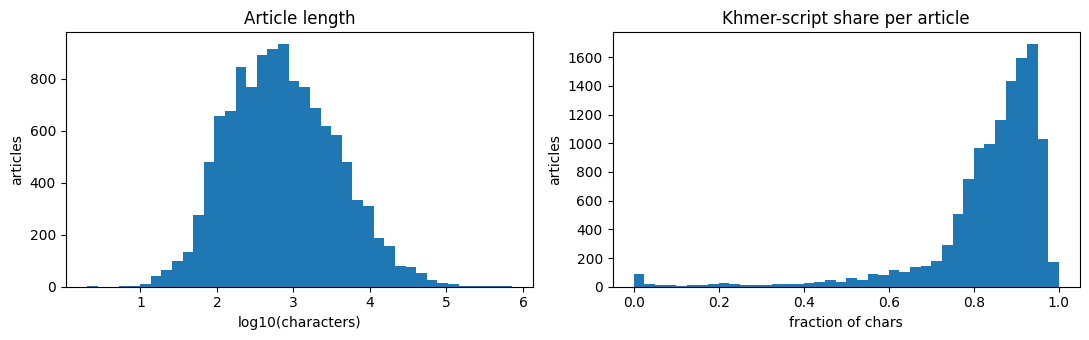


--- sample article ---
ទំព័រដើម
គម្រោងវិគីជាបងប្អូន



<div id="mp_otherLanguages" class="mp_outerbox" style="border:1px solid #a7d7f9; margin: 0.6em; vertical-align:top; padding: 1em; -moz-border-radius: 0.8em; -webkit-border-radius: 0.8em; border-radius: 0.8em;">
វិគីភីឌាជាភាសាដទៃទៀត

km
Khmer
Khmer Wikipedia
Km Wikipedia
Wikipedia
Khmer Wiki
Cambodia Wiki
Cambodian Wiki
Cambodia Wikipedia
kmwiki
km wiki
km
kmwp
វិគីភីឌា
វិគីភ


In [30]:
KHMER_CHAR_RE = re.compile(r"[ក-៿᧠-᧿]")

char_lens = np.array([len(t) for t in raw["text"]])
khmer_share = np.array([len(KHMER_CHAR_RE.findall(t)) / max(len(t), 1) for t in raw["text"]])

print(f"Total characters: {char_lens.sum():,}")
print("Article length (chars) percentiles:",
      {p: int(np.percentile(char_lens, p)) for p in (5, 25, 50, 75, 95)})
print(f"Stub articles (< 500 chars): {(char_lens < 500).mean():.1%}")
print(f"Mean share of Khmer-script characters: {khmer_share.mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(np.log10(char_lens + 1), bins=40)
axes[0].set(title="Article length", xlabel="log10(characters)", ylabel="articles")
axes[1].hist(khmer_share, bins=40)
axes[1].set(title="Khmer-script share per article", xlabel="fraction of chars", ylabel="articles")
plt.tight_layout()
plt.show()

print("\n--- sample article ---")
print(raw[0]["title"])
print(raw[0]["text"][:400])

## 2. Cleaning (Phase 2)

Each article becomes a list of sentences:
- **NFC** Unicode normalization.
- **Zero-width space (U+200B)** becomes a regular space. Khmer writers use it as an invisible word-boundary marker, so it helps the segmenter. Deleting it would glue words together.
- **Sentence splits** happen on `។` (khan), `៕` (bariyoosan), `?`, `!` and newlines.
- **Non-Khmer runs** (Latin, symbols, other punctuation) become a space. Code-mixed text is a PRD non-goal.
- **Digits** (ASCII and Khmer `០-៩`) are kept here and mapped to a single `<num>` token after segmentation.

In [31]:
SENT_SPLIT_RE = re.compile(r"[\n។៕?!]+")                       # newline, ។, ៕, ?, !
INVISIBLE_RE = re.compile(r"[‌‍﻿­឴឵]")    # ZWNJ/ZWJ/BOM/soft hyphen/deprecated inherent vowels
KHMER_PUNCT_RE = re.compile(r"[៖៘-៚]")                    # ៖ ៘ ៙ ៚ (keep ៗ: it attaches to a word)
NON_KHMER_RE = re.compile(r"[^ក-៿᧠-᧿0-9\s]+")
WS_RE = re.compile(r"\s+")


def clean_text(text: str) -> list[str]:
    # Raw text -> list of cleaned sentence strings (still unsegmented).
    text = unicodedata.normalize("NFC", text)
    text = text.replace("​", " ")
    text = INVISIBLE_RE.sub("", text)
    sentences = []
    for chunk in SENT_SPLIT_RE.split(text):
        chunk = NON_KHMER_RE.sub(" ", chunk)
        chunk = KHMER_PUNCT_RE.sub(" ", chunk)
        chunk = WS_RE.sub(" ", chunk).strip()
        if KHMER_CHAR_RE.search(chunk):          # drop digit-only / empty fragments
            sentences.append(chunk)
    return sentences


demo_raw = "ប្រទេសកម្ពុជា​មាន​រាជធានី Phnom Penh ភ្នំពេញ។ ឆ្នាំ ២០២៣ (2023) មានភ្ញៀវទេសចរ!"
for s in clean_text(demo_raw):
    print(repr(s))

'ប្រទេសកម្ពុជា មាន រាជធានី ភ្នំពេញ'
'ឆ្នាំ ២០២៣ 2023 មានភ្ញៀវទេសចរ'


## 3. Word Segmentation (Phase 2)

Uses `khmer-nltk`'s CRF segmenter. On the full corpus this is the slowest step, so results are **cached to JSONL one article at a time and resumable**. If Colab disconnects, rerun the cell and it continues from where it stopped.

In [32]:
from khmernltk import word_tokenize

NUM_TOKEN = "<num>"
DIGIT_RE = re.compile(r"[0-9០-៩]+")


def segment_raw(sentence: str) -> list[str]:
    # khmer-nltk tokens with whitespace tokens dropped (used for the khPOS comparison).
    return [t.strip() for t in word_tokenize(sentence, return_tokens=True) if t.strip()]


def segment_sentence(sentence: str) -> list[str]:
    # Tokens for the language model: digit runs become a single <num>.
    tokens = []
    for tok in segment_raw(sentence):
        if DIGIT_RE.fullmatch(tok):
            if tokens and tokens[-1] == NUM_TOKEN:
                continue                                   # "២០ ២៣" -> one <num>
            tok = NUM_TOKEN
        tokens.append(tok)
    return tokens


def segment_text(text: str) -> list[list[str]]:
    return [toks for s in clean_text(text) if (toks := segment_sentence(s))]


for sample in ["ខ្ញុំចង់ទៅសាលារៀន", demo_raw]:
    print(segment_text(sample))

[['ខ្ញុំ', 'ចង់', 'ទៅ', 'សាលារៀន']]
[['ប្រទេស', 'កម្ពុជា', 'មាន', 'រាជធានី', 'ភ្នំពេញ'], ['ឆ្នាំ', '<num>', 'មាន', 'ភ្ញៀវ', 'ទេសចរ']]


In [33]:
def load_segmented(path: Path) -> dict:
    out = {}
    if path.exists():
        with path.open(encoding="utf-8") as f:
            for line in f:
                try:
                    rec = json.loads(line)
                except json.JSONDecodeError:                 # last line cut off by a session drop
                    continue
                out[rec["id"]] = rec["sentences"]
    return out


segmented = load_segmented(SEG_CACHE)
todo = [a for a in raw if a["id"] not in segmented]
print(f"Cached: {len(segmented):,} | to segment: {len(todo):,}")

t0 = time.time()
with SEG_CACHE.open("a", encoding="utf-8") as f:
    for article in tqdm(todo, desc="Segmenting"):
        sents = [toks for toks in segment_text(article["text"]) if len(toks) >= cfg.min_sentence_tokens]
        segmented[article["id"]] = sents
        f.write(json.dumps({"id": article["id"], "sentences": sents}, ensure_ascii=False) + "\n")
if todo:
    print(f"Segmented {len(todo):,} articles in {time.time() - t0:.1f}s")

n_sents = sum(len(s) for s in segmented.values())
n_tokens = sum(len(t) for s in segmented.values() for t in s)
print(f"{len(segmented):,} articles | {n_sents:,} sentences | {n_tokens:,} word tokens")

Cached: 0 | to segment: 11,994


Segmenting:   0%|          | 0/11994 [00:00<?, ?it/s]

Segmented 11,994 articles in 668.4s
11,994 articles | 308,613 sentences | 6,646,893 word tokens


In [34]:
# Spot-check segmentation by eye (PRD: review ~50-100 sentences). "|" marks word boundaries.
rng = random.Random(cfg.seed)
all_sents = [s for sents in segmented.values() for s in sents]
for toks in rng.sample(all_sents, k=min(15, len(all_sents))):
    print(" | ".join(toks))

ពាក្យ | នេះ | ប្រើ | នៅក្នុង | សាសនា | ហិណ្ឌូ | គឺ | សម្រាប់ | ព្រះវិស្ណុ | អាទិទេព | មួយ | អង្គ | ក្នុង | សាសនា | ហិណ្ឌូ | ដែល | ត្រូវបាន | គេ | គោរព | បូជា | ជា | ព្រះអាទិទេព | ដែល | មាន | ឋានៈ | ខ្ពស់ | ជាង | គេ
អ្នកឯកទេស | ដែល | ត្រូវបាន | ជួប | សម្ភាសន៍ | នៅ | ទីស្នាក់ការ | អង្គការ | សុខភាព | ពិភពលោក | ក្នុង | ទីក្រុង | ហ្សឺណែវ | ខែកុម្ភៈ | ឆ្នាំ | <num> | បាន | រាយការណ៍ | ថា | ដំណើរការងារ | របស់ | ពួកគេ | ទៅ | លើ | វ៉ាក់សាំង | ជំងឺ | ផ្ដាសាយ | ទូទៅ | កាន់តែ | មាន | ការរីកចម្រើន | ទៅ | មុខ | ជាលំដាប់ | ហើយ
ឧបករណ៍ | តន្ត្រី | ខ្មែរ
គាត់ | ជា | សម្ដេច | ប៉ាប | ថ្មី | ជាង | គេ | ដែល | ជ្រើស | ពី | សន្ត | យូហាន | ទៅ | ជា | សម្ដេច | ប៉ាប
នៅ | ពេល | ដែល | ពួកគេ | មាន | ចំនេះ | ដឹង | ជ្រៅ | ជ្រេះ | ហើយ | នោះ
យ៉ាងណា | ក៏ដោយ | ដី | ដែល | បាន | ប្រគល់ | ឲ | ក្រុមគ្រួសារ | ឥស្សរជន | បាន | កាត់បន្ថយ | ពន្ធ | ដី | បន្តិច | ម្ដង | ៗ
សិទ្ធិ | នេះ | បញ្ចប់ | នៅពេល | មរណភាព | នៃ | អត្ថគាហកៈ | ឬ | ដោយ | អនុវត្ត | តាម | លក្ខខណ្ឌ | នៃ | កិច្ចសន្យា
នៅក្នុង | ខែសីហា | ឆ្នាំ | <num> | វា | ត្រូវបាន | គេ

### 3a. Optional: extra training text (FineWeb-2 Khmer)

The smoke run overfit badly (train ppl 82 vs val 232), so more data is the most reliable improvement after using the full Wikipedia corpus. Set `cfg.extra_docs` (e.g. `20_000`) to stream that many Khmer web documents from [FineWeb-2](https://huggingface.co/datasets/HuggingFaceFW/fineweb-2) (`khm_Khmr`). They go through the same clean → segment pipeline and are cached the same resumable way.

- The extra text is added to the **training split only**. Val/test stay pure Wikipedia, so results remain comparable with Wikipedia-only runs.
- Web crawls contain Wikipedia mirrors, so any extra sentence that exactly matches a val/test sentence is dropped (Section 4).
- Web text is noisier and more informal than Wikipedia. Compare val perplexity with and without it before keeping it.

In [35]:
extra_sentences = []
if cfg.extra_docs:
    extra_cached = load_segmented(EXTRA_SEG_CACHE)        # ids extra-0 ... extra-(n-1), written in order
    start = len(extra_cached)
    if start < cfg.extra_docs:
        web = load_dataset(cfg.extra_dataset, name=cfg.extra_config, split="train", streaming=True).skip(start)
        with EXTRA_SEG_CACHE.open("a", encoding="utf-8") as f:
            for i, doc in zip(range(start, cfg.extra_docs),
                              tqdm(web, total=cfg.extra_docs - start, desc="Segmenting extra")):
                sents = [t for t in segment_text(doc["text"]) if len(t) >= cfg.min_sentence_tokens]
                extra_cached[f"extra-{i}"] = sents
                f.write(json.dumps({"id": f"extra-{i}", "sentences": sents}, ensure_ascii=False) + "\n")
    extra_sentences = [s for i in range(cfg.extra_docs) for s in extra_cached.get(f"extra-{i}", [])]
    print(f"Extra corpus: {cfg.extra_docs:,} docs | {len(extra_sentences):,} sentences | "
          f"{sum(map(len, extra_sentences)):,} tokens")
else:
    print("No extra corpus (cfg.extra_docs = 0).")

No extra corpus (cfg.extra_docs = 0).


### 3b. Segmentation quality vs. khPOS (Phase 4 metric, set up now)

Word-level precision/recall/F1 using character-span matching: a predicted word counts as correct only if both of its boundaries match a gold word. To run it, download [khPOS](https://github.com/ye-kyaw-thu/khPOS) and set `KHPOS_PATH`. The loader expects one sentence per line with space-separated `word/TAG` tokens; check this against the file you download.

> Caveat for the report: if khmer-nltk's training data overlaps with khPOS, this score will be optimistic.

In [36]:
KHPOS_PATH = ARTIFACT_DIR / f"khPOS/train.all2"   # e.g. Path("khPOS/corpus-draft-ver-1.0/data/after-replace/train.all2")


def to_spans(tokens):
    spans, pos = set(), 0
    for t in tokens:
        spans.add((pos, pos + len(t)))
        pos += len(t)
    return spans


def segmentation_prf(gold_sents, pred_sents):
    tp = n_pred = n_gold = 0
    for gold, pred in zip(gold_sents, pred_sents):
        g, p = to_spans(gold), to_spans(pred)
        tp += len(g & p)
        n_pred += len(p)
        n_gold += len(g)
    precision, recall = tp / max(n_pred, 1), tp / max(n_gold, 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-12)
    return {"precision": precision, "recall": recall, "f1": f1}


def load_khpos(path, limit=None):
    sents = []
    with open(path, encoding="utf-8") as f:
        for line in f:
            words = [unicodedata.normalize("NFC", tok.rsplit("/", 1)[0]).replace("​", "")
                     for tok in line.split()]
            words = [w for w in words if w]
            if words:
                sents.append(words)
            if limit and len(sents) >= limit:
                break
    return sents


# Sanity check of the metric itself
print(segmentation_prf([["ខ្ញុំ", "ចង់", "ទៅ"]], [["ខ្ញុំ", "ចង់ទៅ"]]))   # P=0.5, R=0.33

if KHPOS_PATH:
    gold = load_khpos(KHPOS_PATH)
    pred = [segment_raw("".join(g)) for g in tqdm(gold, desc="Segmenting khPOS")]
    print(f"khPOS ({len(gold):,} sentences):", segmentation_prf(gold, pred))

{'precision': 0.5, 'recall': 0.3333333333333333, 'f1': 0.4}


Segmenting khPOS:   0%|          | 0/12000 [00:00<?, ?it/s]

khPOS (12,000 sentences): {'precision': 0.6145875800472914, 'recall': 0.7594261755109316, 'f1': 0.679372959031567}


#### Why is segmentation F1 below target? (diagnostic)

Precision is below recall on khPOS, which means khmer-nltk produces **more** words than the gold standard. This cell checks which of two explanations fits:
- **Loader/normalization bug.** The characters of the gold and predicted segmentations should be identical. If many sentences differ, the khPOS file format doesn't match what `load_khpos` assumes; look at the printed examples.
- **Convention difference.** If the errors are mostly consistent splits of compounds (gold `សាលារៀន` → predicted `សាលា | រៀន`), the two tools just define "word" differently. Report that as a known limitation; it is not random noise. For next-word prediction it mostly means the model suggests shorter units.

In [37]:
if KHPOS_PATH and Path(KHPOS_PATH).exists():
    text_mismatch = [(g, p) for g, p in zip(gold, pred) if "".join(g) != "".join(p)]
    print(f"Sentences whose characters differ between gold and prediction: {len(text_mismatch):,} / {len(gold):,}")
    for g, p in text_mismatch[:3]:
        print("  gold:", " | ".join(g)[:150], "\n  pred:", " | ".join(p)[:150])

    over, under = Counter(), Counter()     # over: one gold word split into several; under: several merged into one
    for g, p in zip(gold, pred):
        if "".join(g) != "".join(p):
            continue
        text, gs, ps = "".join(g), to_spans(g), to_spans(p)
        for spans_a, spans_b, bucket in ((gs - ps, ps, over), (ps - gs, gs, under)):
            for a, b in spans_a:
                inner = sorted((s, e) for s, e in spans_b if a <= s and e <= b)
                if len(inner) > 1 and sum(e - s for s, e in inner) == b - a:
                    bucket[(text[a:b], " | ".join(text[s:e] for s, e in inner))] += 1

    print(f"\nOver-segmentation (gold word split): {sum(over.values()):,} | "
          f"under-segmentation (gold words merged): {sum(under.values()):,}")
    for title, bucket in (("Most common splits (gold -> pred)", over), ("Most common merges (pred <- gold)", under)):
        print(f"\n{title}:")
        for (word, pieces), n in bucket.most_common(15):
            print(f"  {n:>5}  {word}  ->  {pieces}")

Sentences whose characters differ between gold and prediction: 0 / 12,000

Over-segmentation (gold word split): 23,377 | under-segmentation (gold words merged): 2,484

Most common splits (gold -> pred):
    974  លោក~ស្រី  ->  លោក | ~ | ស្រី
    955  លោក~ជំទាវ  ->  លោក | ~ជំទាវ
    926  ឯក_ឧត្ដម  ->  ឯក_ | ឧត្ដម
    918  អ្នក~នាង  ->  អ្នក~ | នាង
    884  គឺ_ជា  ->  គឺ | _ | ជា
    492  ត្រូវ_បាន  ->  ត្រូវ | _ | បាន
    264  នៅ_ក្នុង  ->  នៅ_ | ក្នុង
    156  ប្រជា_ពល_រដ្ឋ  ->  ប្រជា_ពល_ | រដ្ឋ
    151  ទាំង_នោះ  ->  ទាំង_ | នោះ
    147  ពួក_គេ  ->  ពួក_ | គេ
    132  ផង_ដែរ  ->  ផង | _ | ដែរ
    129  កាល_ពី  ->  កាល | _ | ពី
    122  ជា_ច្រើន  ->  ជា_ | ច្រើន
    116  ការ~ប្រកួត  ->  ការ~ | ប្រកួត
    114  កាល_ពី  ->  កាល_ | ពី

Most common merges (pred <- gold):
    299  ថា៖  ->  ថា | ៖
     31  សហប្រជា_ជាតិ  ->  សហ | ប្រជា_ជាតិ
     30  ទី១  ->  ទី | ១
     26  ទី២  ->  ទី | ២
     19  អនុប្រធាន  ->  អនុ | ប្រធាន
     19  ទី៣  ->  ទី | ៣
     19  ពួកគេ  ->  ពួក | គេ
     18  »៕  -> 

## 4. Train / Validation / Test Split — by article

This split happens **before** vocabulary building, so nothing from val/test leaks into training.

In [38]:
article_ids = sorted(segmented)
random.Random(cfg.seed).shuffle(article_ids)
n_val = max(1, int(len(article_ids) * cfg.val_frac))
n_test = max(1, int(len(article_ids) * cfg.test_frac))
split_ids = {
    "val": article_ids[:n_val],
    "test": article_ids[n_val:n_val + n_test],
    "train": article_ids[n_val + n_test:],
}
splits = {name: [s for aid in ids for s in segmented[aid]] for name, ids in split_ids.items()}

if extra_sentences:                                       # train only; drop exact copies of val/test sentences
    held_out = {tuple(s) for name in ("val", "test") for s in splits[name]}
    kept = [s for s in extra_sentences if tuple(s) not in held_out]
    print(f"Extra corpus -> train: {len(kept):,} sentences "
          f"({len(extra_sentences) - len(kept):,} dropped as exact val/test duplicates)")
    splits["train"] = splits["train"] + kept
for name, sents in splits.items():
    print(f"{name:>5}: {len(split_ids[name]):>6,} articles | {len(sents):>8,} sentences | "
          f"{sum(map(len, sents)):>10,} tokens")

  val:    599 articles |   11,631 sentences |    237,523 tokens
 test:    599 articles |   12,739 sentences |    254,675 tokens
train: 10,796 articles |  284,243 sentences |  6,154,695 tokens


## 5. Vocabulary (frequency cutoff + `<unk>`)

In [39]:
class Vocab:
    PAD, UNK, EOS = "<pad>", "<unk>", "<eos>"
    SPECIALS = (PAD, UNK, EOS)

    def __init__(self, itos):
        self.itos = list(itos)
        self.stoi = {w: i for i, w in enumerate(self.itos)}
        self.pad_id, self.unk_id, self.eos_id = (self.stoi[t] for t in self.SPECIALS)

    @classmethod
    def build(cls, sentences, min_freq, max_size):
        counts = Counter(w for s in sentences for w in s)
        words = [w for w, c in counts.most_common(max_size - len(cls.SPECIALS)) if c >= min_freq]
        return cls([*cls.SPECIALS, *words]), counts

    def encode(self, tokens):
        return [self.stoi.get(t, self.unk_id) for t in tokens]

    def decode(self, ids):
        return [self.itos[i] for i in ids]

    def __len__(self):
        return len(self.itos)


vocab, train_counts = Vocab.build(splits["train"], cfg.min_freq, cfg.max_vocab)
special_ids = torch.tensor([vocab.stoi[t] for t in Vocab.SPECIALS])

train_total = sum(train_counts.values())
covered = sum(c for w, c in train_counts.items() if w in vocab.stoi)
print(f"Distinct train words: {len(train_counts):,} -> vocab size {len(vocab):,}")
print(f"Train token coverage: {covered / train_total:.2%}")
for name in ("val", "test"):
    toks = [w for s in splits[name] for w in s]
    oov = sum(w not in vocab.stoi for w in toks) / max(len(toks), 1)
    print(f"{name} OOV rate (-> <unk>): {oov:.2%}")
print("Most frequent:", [w for w, _ in train_counts.most_common(20)])

Distinct train words: 111,960 -> vocab size 30,000
Train token coverage: 98.09%
val OOV rate (-> <unk>): 2.68%
test OOV rate (-> <unk>): 2.82%
Most frequent: ['<num>', 'បាន', 'មាន', 'ជា', 'ដែល', 'និង', 'នៅ', 'ក្នុង', 'របស់', 'ថា', 'នេះ', 'ទៅ', 'ហើយ', 'នៃ', 'ដោយ', 'នោះ', 'មិន', 'ក៏', 'ឆ្នាំ', 'មួយ']


## 6. Training Sequences

Each split becomes one flat stream of ids, with `<eos>` before the first sentence and after every sentence: `<eos> s1 <eos> s2 <eos> …`. The stream is cut into non-overlapping chunks of `SEQ_LEN + 1`. Inputs are `chunk[:-1]` and targets are `chunk[1:]`, so every position is a (context → next word) pair.

In [40]:
def encode_split(sentences, vocab):
    ids = [vocab.eos_id]
    for s in sentences:
        ids.extend(vocab.encode(s))
        ids.append(vocab.eos_id)
    return torch.tensor(ids, dtype=torch.long)


class LMChunkDataset(Dataset):
    def __init__(self, stream: torch.Tensor, seq_len: int):
        self.stream, self.seq_len, self.offset = stream, seq_len, 0

    def set_random_offset(self, rng):
        # Shift chunk boundaries so each epoch sees different (context, target) groupings.
        self.offset = rng.randrange(self.seq_len)

    def __len__(self):
        return (len(self.stream) - 1 - self.offset) // self.seq_len

    def __getitem__(self, i):
        start = self.offset + i * self.seq_len
        chunk = self.stream[start:start + self.seq_len + 1]
        return chunk[:-1], chunk[1:]


def make_loaders(cfg):
    # Built per run, so sweeps can change seq_len / batch_size without touching the streams.
    kw = dict(batch_size=cfg.batch_size, num_workers=0, pin_memory=device.type == "cuda")
    ds = {name: LMChunkDataset(stream, cfg.seq_len) for name, stream in streams.items()}
    return {
        "train": DataLoader(ds["train"], shuffle=True, drop_last=True, **kw),
        "val": DataLoader(ds["val"], shuffle=False, **kw),
        "test": DataLoader(ds["test"], shuffle=False, **kw),
    }


streams = {name: encode_split(sents, vocab) for name, sents in splits.items()}
loaders = make_loaders(cfg)
for name, loader in loaders.items():
    print(f"{name:>5}: {len(streams[name]):>10,} ids -> {len(loader.dataset):>8,} chunks")

x, y = loaders["train"].dataset[0]
print("\ncontext:", " ".join(vocab.decode(x[:10].tolist())))
print("target :", " ".join(vocab.decode(y[:10].tolist())))
assert torch.equal(x[1:], y[:-1]), "targets must be inputs shifted by one"

train:  6,438,939 ids ->  201,216 chunks
  val:    249,155 ids ->    7,786 chunks
 test:    267,415 ids ->    8,356 chunks

context: <eos> ក្នុង គណិតវិទ្យា អនុគមន៍ ដសុន គឺ <eos> សញ្ញាណ គឺ ត្រូវបាន
target : ក្នុង គណិតវិទ្យា អនុគមន៍ ដសុន គឺ <eos> សញ្ញាណ គឺ ត្រូវបាន ប្រើ


## 7. LSTM Language Model (Phase 3)

`embedding (+ embedding dropout) → dropout → LSTM (stacked) → dropout → [projection] → linear decoder`

**Embedding dropout** (from AWD-LSTM) zeroes entire rows of the embedding matrix during training, so every occurrence of a dropped word disappears in that batch. The model can't over-rely on any single word's vector, which helps on a small corpus with a long tail of rare words.

With `tie_weights=True` the decoder reuses the embedding matrix, and a small projection maps `hidden_dim → embed_dim` when the two sizes differ. This removes about `vocab × hidden` parameters and usually lowers perplexity on small corpora.

In [41]:
class LSTMLanguageModel(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_layers, dropout, tie_weights, pad_id,
                 embed_dropout=0.0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=pad_id)
        self.embed_dropout = embed_dropout
        self.drop = nn.Dropout(dropout)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, num_layers, batch_first=True,
                            dropout=dropout if num_layers > 1 else 0.0)
        out_dim = hidden_dim
        self.proj = None
        if tie_weights and hidden_dim != embed_dim:
            self.proj = nn.Linear(hidden_dim, embed_dim)
            out_dim = embed_dim
        self.decoder = nn.Linear(out_dim, vocab_size)
        if tie_weights:
            self.decoder.weight = self.embedding.weight

    def embed(self, x):
        if not (self.training and self.embed_dropout > 0):
            return self.embedding(x)
        w = self.embedding.weight
        keep = w.new_empty(w.size(0), 1).bernoulli_(1 - self.embed_dropout) / (1 - self.embed_dropout)
        return F.embedding(x, w * keep, self.embedding.padding_idx)

    def forward(self, x, hidden=None):
        # x: (batch, seq) -> logits: (batch, seq, vocab)
        out, hidden = self.lstm(self.drop(self.embed(x)), hidden)
        out = self.drop(out)
        if self.proj is not None:
            out = self.proj(out)
        return self.decoder(out), hidden


def build_model(cfg, vocab):
    return LSTMLanguageModel(len(vocab), cfg.embed_dim, cfg.hidden_dim, cfg.num_layers, cfg.dropout,
                             cfg.tie_weights, vocab.pad_id, cfg.embed_dropout).to(device)


model = build_model(cfg, vocab)
print(model)
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

# Shape smoke test
with torch.no_grad():
    logits, _ = model(x.unsqueeze(0).to(device))
assert logits.shape == (1, cfg.seq_len, len(vocab)), logits.shape

LSTMLanguageModel(
  (embedding): Embedding(30000, 256, padding_idx=0)
  (drop): Dropout(p=0.3, inplace=False)
  (lstm): LSTM(256, 512, num_layers=2, batch_first=True, dropout=0.3)
  (proj): Linear(in_features=512, out_features=256, bias=True)
  (decoder): Linear(in_features=256, out_features=30000, bias=True)
)
Trainable parameters: 11,519,536


## 8. Evaluation Metrics & Unigram Baseline (Phase 4, defined before training)

Two views of accuracy:
- **all**: every target, including `<unk>` and `<eos>`. Perplexity is reported on this view (standard LM perplexity).
- **words**: targets that are real words only (no `<unk>`/`<eos>`), with special tokens removed from the candidate list. This is what a keyboard user would actually see, so use it for the PRD's top-3/top-5 targets.

Perplexity is only comparable between models that share the same vocabulary, so the unigram baseline uses the same `vocab`.

In [42]:
def amp_ctx():
    # Mixed precision on CUDA only; cross-entropy/softmax are still computed in float32 by autocast.
    return torch.autocast(device_type=device.type, dtype=torch.float16,
                          enabled=cfg.use_amp and device.type == "cuda")


def _accumulate_topk(logits, y, stats, special_ids):
    # Update top-k hit counts for one batch of flattened logits (N, V) and targets (N,).
    max_k = max(TOP_KS)
    hits = logits.topk(max_k, dim=-1).indices == y[:, None]
    word_mask = ~torch.isin(y, special_ids)
    masked = logits[word_mask].clone()
    masked[:, special_ids] = float("-inf")
    word_hits = masked.topk(max_k, dim=-1).indices == y[word_mask][:, None]
    for k in TOP_KS:
        stats[f"top{k}_all"] += hits[:, :k].any(dim=1).sum().item()
        stats[f"top{k}_words"] += word_hits[:, :k].any(dim=1).sum().item()
    stats["n_all"] += y.numel()
    stats["n_words"] += word_mask.sum().item()


def _finalize(stats, nll_sum):
    out = {"ppl": math.exp(nll_sum / max(stats["n_all"], 1))}
    for k in TOP_KS:
        out[f"top{k}_all"] = stats[f"top{k}_all"] / max(stats["n_all"], 1)
        out[f"top{k}_words"] = stats[f"top{k}_words"] / max(stats["n_words"], 1)
    return out


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    sids = special_ids.to(device)
    stats, nll_sum = Counter(), 0.0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        with amp_ctx():
            logits, _ = model(x)
        logits, y = logits.float().reshape(-1, logits.size(-1)), y.reshape(-1)
        nll_sum += F.cross_entropy(logits, y, reduction="sum").item()
        _accumulate_topk(logits, y, stats, sids)
    return _finalize(stats, nll_sum)


def unigram_baseline(train_stream, eval_stream, vocab_size, pad_id):
    # Context-free model: P(w) = add-one smoothed train frequency.
    counts = torch.bincount(train_stream[1:], minlength=vocab_size).float() + 1.0
    counts[pad_id] = 0.0
    log_probs = (counts / counts.sum()).log()
    y = eval_stream[1:]
    logits = log_probs.expand(len(y), -1)     # same prediction for every position (no copy)
    stats = Counter()
    for i in range(0, len(y), 4096):
        _accumulate_topk(logits[i:i + 4096], y[i:i + 4096], stats, special_ids)
    return _finalize(stats, -log_probs[y].sum().item())


def fmt(m):
    return " | ".join(f"{k} {v:.2f}" if k == "ppl" else f"{k} {v:.1%}" for k, v in m.items())


baseline_val = unigram_baseline(streams["train"], streams["val"], len(vocab), vocab.pad_id)
print("Unigram baseline (val):", fmt(baseline_val))
print("Untrained LSTM   (val):", fmt(evaluate(model, loaders["val"])))

Unigram baseline (val): ppl 1171.32 | top1_all 4.7% | top1_words 2.4% | top3_all 9.4% | top3_words 6.0% | top5_all 12.8% | top5_words 9.4%
Untrained LSTM   (val): ppl 34319.66 | top1_all 0.0% | top1_words 0.0% | top3_all 0.0% | top3_words 0.0% | top5_all 0.0% | top5_words 0.0%


## 9. Training (Phase 3)

`train_model(cfg, run_name)` trains one configuration and saves checkpoints under `CKPT_DIR/<run_name>/`:
- **AdamW** with weight decay, **gradient clipping** (needed for LSTMs), and **mixed precision** on GPU.
- The LR is halved when val perplexity plateaus, with early stopping after `patience` epochs.
- **Random chunk offsets** each epoch, so the model doesn't see the same 32-word windows every time.
- **Resumable.** `last.pt` is written every epoch, and a rerun continues if the config and vocab are unchanged (`epochs`/`patience` may change). Rerunning a finished run just reloads it.

In [43]:
RESUME_IGNORED_KEYS = {"epochs", "patience", "resume"}


def _same_run(a: dict, b: dict) -> bool:
    strip = lambda d: {k: v for k, v in d.items() if k not in RESUME_IGNORED_KEYS}
    return strip(a) == strip(b)


def train_model(cfg, run_name):
    # Train one configuration; returns (model loaded with its best weights, history, best checkpoint path).
    set_seed(cfg.seed)
    run_dir = CKPT_DIR / run_name
    run_dir.mkdir(parents=True, exist_ok=True)
    last_path, best_path = run_dir / "last.pt", run_dir / "best.pt"

    run_loaders = make_loaders(cfg)
    model = build_model(cfg, vocab)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=1)
    scaler = torch.amp.GradScaler("cuda", enabled=cfg.use_amp and device.type == "cuda")
    offset_rng = random.Random(cfg.seed)

    def save(path, epoch):
        torch.save({
            "model": model.state_dict(), "optimizer": optimizer.state_dict(),
            "scheduler": scheduler.state_dict(), "scaler": scaler.state_dict(), "epoch": epoch,
            "best_val_ppl": best_val_ppl, "bad_epochs": bad_epochs, "history": history,
            "config": asdict(cfg), "vocab": vocab.itos,
        }, path)

    start_epoch, best_val_ppl, history, bad_epochs = 0, float("inf"), [], 0
    if cfg.resume and last_path.exists():
        ckpt = torch.load(last_path, map_location=device)
        if ckpt["vocab"] == vocab.itos and _same_run(ckpt["config"], asdict(cfg)):
            model.load_state_dict(ckpt["model"])
            optimizer.load_state_dict(ckpt["optimizer"])
            scheduler.load_state_dict(ckpt["scheduler"])
            if ckpt["scaler"]:                              # empty when AMP was off
                scaler.load_state_dict(ckpt["scaler"])
            start_epoch, best_val_ppl = ckpt["epoch"] + 1, ckpt["best_val_ppl"]
            history, bad_epochs = ckpt["history"], ckpt["bad_epochs"]
            print(f"[{run_name}] resumed after epoch {start_epoch} (best val ppl {best_val_ppl:.2f})")
        else:
            print(f"[{run_name}] checkpoint has a different config or vocab - starting fresh.")

    for epoch in range(start_epoch, cfg.epochs):
        if bad_epochs >= cfg.patience:
            break                                             # already early-stopped before a resume
        if cfg.random_offset:
            run_loaders["train"].dataset.set_random_offset(offset_rng)
        model.train()
        t0, total_loss, n_batches = time.time(), 0.0, 0
        pbar = tqdm(run_loaders["train"], desc=f"{run_name} epoch {epoch + 1}", leave=False)
        for x, y in pbar:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with amp_ctx():
                logits, _ = model(x)
                loss = criterion(logits.reshape(-1, logits.size(-1)), y.reshape(-1))
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip)
            scaler.step(optimizer)
            scaler.update()
            total_loss += loss.item()
            n_batches += 1
            if n_batches % 50 == 0:
                pbar.set_postfix(ppl=f"{math.exp(total_loss / n_batches):.1f}")
        train_ppl = math.exp(total_loss / max(n_batches, 1))

        val = evaluate(model, run_loaders["val"])
        scheduler.step(val["ppl"])
        history.append({"epoch": epoch + 1, "train_ppl": train_ppl, **val,
                        "lr": optimizer.param_groups[0]["lr"], "seconds": time.time() - t0})
        print(f"[{run_name}] epoch {epoch + 1:>2} | {time.time() - t0:5.0f}s | train ppl {train_ppl:8.2f} | val {fmt(val)}")

        improved = val["ppl"] < best_val_ppl
        best_val_ppl = min(best_val_ppl, val["ppl"])
        bad_epochs = 0 if improved else bad_epochs + 1
        save(last_path, epoch)
        if improved:
            save(best_path, epoch)
        if bad_epochs >= cfg.patience:
            print(f"[{run_name}] early stopping: no val improvement for {cfg.patience} epochs.")
            break

    model.load_state_dict(torch.load(best_path, map_location=device)["model"])
    model.eval()
    return model, history, best_path

### 9a. Hyperparameter sweep (optional)

Changes **one setting at a time** from the current `Config` and trains each variant for a few epochs. That's far cheaper than a full grid and still shows which settings matter. Runs are resumable, so if Colab disconnects, rerun the cell and finished runs are skipped.

How to use it:
1. Run the sweep and copy the settings that lowered val perplexity into `Config`. Combine a few winners and check that the combination also helps.
2. Rerun from Section 0, then train the main model (9b).

Caveats:
- **Short runs favor fast learners.** Higher dropout or bigger models often look worse after 3–4 epochs and win later, so treat close results as ties.
- **Don't sweep `min_freq`/`max_vocab` here.** They change the vocabulary, and perplexities over different vocabularies aren't comparable. Use the top-k "words" accuracy for that decision instead.

In [44]:
from dataclasses import replace

RUN_SWEEP = True
SWEEP_EPOCHS = 4
SWEEP = [
    {},                                  # current Config (reference point)
    {"dropout": 0.5},
    {"embed_dropout": 0.0},
    {"hidden_dim": 1024},
    {"num_layers": 3},
    {"seq_len": 64},
    {"lr": 2e-3},
    {"embed_dim": 512, "hidden_dim": 512},
]

if RUN_SWEEP:
    rows = []
    for overrides in SWEEP:
        run_cfg = replace(cfg, epochs=SWEEP_EPOCHS, patience=SWEEP_EPOCHS, **overrides)
        name = "sweep_" + ("_".join(f"{k}={v}" for k, v in overrides.items()) or "base")
        sweep_model, hist, _ = train_model(run_cfg, name)
        best = min(hist, key=lambda h: h["ppl"])
        rows.append({"run": name, "params": sum(p.numel() for p in sweep_model.parameters()),
                     "min/epoch": np.mean([h["seconds"] for h in hist]) / 60, **best})
        del sweep_model
        if device.type == "cuda":
            torch.cuda.empty_cache()

    rows.sort(key=lambda r: r["ppl"])
    print(f"\n{'run':<40}{'params':>12}{'min/epoch':>11}{'val ppl':>10}{'top3_words':>12}{'top5_words':>12}")
    for r in rows:
        print(f"{r['run']:<40}{r['params']:>12,}{r['min/epoch']:>11.1f}{r['ppl']:>10.2f}"
              f"{r['top3_words']:>12.1%}{r['top5_words']:>12.1%}")
    with open(ARTIFACT_DIR / f"sweep_{RUN_TAG}.json", "w") as f:
        json.dump(rows, f, indent=2)

sweep_base epoch 1:   0%|          | 0/3144 [00:00<?, ?it/s]

[sweep_base] epoch  1 |    86s | train ppl   638.60 | val ppl 287.46 | top1_all 15.8% | top1_words 14.5% | top3_all 25.8% | top3_words 23.8% | top5_all 31.3% | top5_words 28.9%


sweep_base epoch 2:   0%|          | 0/3144 [00:00<?, ?it/s]

[sweep_base] epoch  2 |    86s | train ppl   342.98 | val ppl 212.26 | top1_all 17.5% | top1_words 16.3% | top3_all 28.2% | top3_words 26.5% | top5_all 34.1% | top5_words 31.9%


sweep_base epoch 3:   0%|          | 0/3144 [00:00<?, ?it/s]

[sweep_base] epoch  3 |    86s | train ppl   273.92 | val ppl 181.40 | top1_all 18.5% | top1_words 17.4% | top3_all 29.5% | top3_words 27.8% | top5_all 35.3% | top5_words 33.3%


... (54 outputs left out)

sweep_embed_dim=512_hidden_dim=512 epoch 3:   0%|          | 0/3144 [00:00<?, ?it/s]

[sweep_embed_dim=512_hidden_dim=512] epoch  3 |   115s | train ppl   289.71 | val ppl 174.73 | top1_all 19.1% | top1_words 18.1% | top3_all 30.4% | top3_words 28.8% | top5_all 36.3% | top5_words 34.4%


sweep_embed_dim=512_hidden_dim=512 epoch 4:   0%|          | 0/3144 [00:00<?, ?it/s]

[sweep_embed_dim=512_hidden_dim=512] epoch  4 |   115s | train ppl   248.48 | val ppl 156.87 | top1_all 19.9% | top1_words 18.8% | top3_all 31.4% | top3_words 29.8% | top5_all 37.4% | top5_words 35.5%

run                                           params  min/epoch   val ppl  top3_words  top5_words
sweep_hidden_dim=1024                     21,620,272        2.1    137.16       31.6%       37.4%
sweep_lr=0.002                            11,519,536        1.4    145.03       29.7%       35.5%
sweep_embed_dropout=0.0                   11,519,536        1.4    154.66       29.7%       35.4%
sweep_embed_dim=512_hidden_dim=512        19,592,496        1.9    156.87       29.8%       35.5%
sweep_num_layers=3                        13,620,784        1.6    159.70       29.2%       34.8%
sweep_base                                11,519,536        1.4    163.32       28.8%       34.5%
sweep_seq_len=64                          11,519,536        1.2    167.44       29.0%       34.6%
sweep_dropout=

### 9b. Train the main model

In [46]:
model, history, BEST_CKPT = train_model(cfg, "main")
LAST_CKPT = BEST_CKPT.with_name("last.pt")

main epoch 1:   0%|          | 0/3144 [00:00<?, ?it/s]

[main] epoch  1 |    87s | train ppl   638.60 | val ppl 287.46 | top1_all 15.8% | top1_words 14.5% | top3_all 25.8% | top3_words 23.8% | top5_all 31.3% | top5_words 28.9%


main epoch 2:   0%|          | 0/3144 [00:00<?, ?it/s]

[main] epoch  2 |    87s | train ppl   342.98 | val ppl 212.26 | top1_all 17.5% | top1_words 16.3% | top3_all 28.2% | top3_words 26.5% | top5_all 34.1% | top5_words 31.9%


main epoch 3:   0%|          | 0/3144 [00:00<?, ?it/s]

[main] epoch  3 |    88s | train ppl   273.92 | val ppl 181.40 | top1_all 18.5% | top1_words 17.4% | top3_all 29.5% | top3_words 27.8% | top5_all 35.3% | top5_words 33.3%


... (20 outputs left out)

main epoch 14:   0%|          | 0/3144 [00:00<?, ?it/s]

[main] epoch 14 |    87s | train ppl   138.66 | val ppl 109.56 | top1_all 22.9% | top1_words 22.0% | top3_all 34.8% | top3_words 33.4% | top5_all 40.9% | top5_words 39.2%


main epoch 15:   0%|          | 0/3144 [00:00<?, ?it/s]

[main] epoch 15 |    87s | train ppl   135.06 | val ppl 107.45 | top1_all 23.1% | top1_words 22.1% | top3_all 35.0% | top3_words 33.5% | top5_all 41.1% | top5_words 39.4%


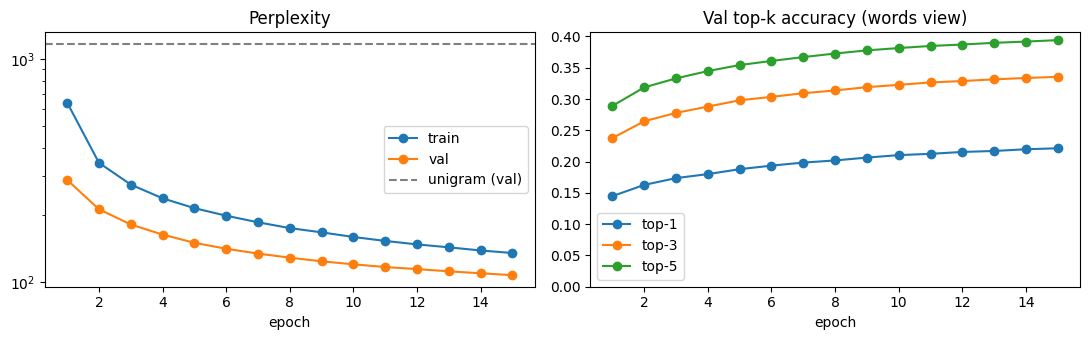

In [47]:
if history:
    ep = [h["epoch"] for h in history]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    axes[0].plot(ep, [h["train_ppl"] for h in history], marker="o", label="train")
    axes[0].plot(ep, [h["ppl"] for h in history], marker="o", label="val")
    axes[0].axhline(baseline_val["ppl"], ls="--", c="gray", label="unigram (val)")
    axes[0].set(title="Perplexity", xlabel="epoch", yscale="log")
    axes[0].legend()
    for k in TOP_KS:
        axes[1].plot(ep, [h[f"top{k}_words"] for h in history], marker="o", label=f"top-{k}")
    axes[1].set(title="Val top-k accuracy (words view)", xlabel="epoch", ylim=(0, None))
    axes[1].legend()
    plt.tight_layout()
    plt.show()

## 10. Final Evaluation on the Test Split (Phase 4)

Loads the **best** checkpoint and compares it against the unigram baseline. PRD targets (words view): top-3 ≥ 25–30%, top-5 ≥ 35–40%, perplexity below the unigram baseline.

In [48]:
def load_for_inference(path):
    ckpt = torch.load(path, map_location=device)
    c, v = Config(**ckpt["config"]), Vocab(ckpt["vocab"])
    m = build_model(c, v)
    m.load_state_dict(ckpt["model"])
    m.eval()
    return m, v, c


if BEST_CKPT.exists():
    model, vocab, _ = load_for_inference(BEST_CKPT)

results = {
    "unigram": unigram_baseline(streams["train"], streams["test"], len(vocab), vocab.pad_id),
    "lstm": evaluate(model, loaders["test"]),
}
cols = ["ppl"] + [f"top{k}_words" for k in TOP_KS] + [f"top{k}_all" for k in TOP_KS]
print(f"{'model':<10}" + "".join(f"{c:>13}" for c in cols))
for name, m in results.items():
    print(f"{name:<10}" + "".join(f"{m[c]:>13.2f}" if c == "ppl" else f"{m[c]:>13.1%}" for c in cols))

with open(ARTIFACT_DIR / f"test_results_{RUN_TAG}.json", "w") as f:
    json.dump(results, f, indent=2)

model               ppl   top1_words   top3_words   top5_words     top1_all     top3_all     top5_all
unigram         1226.65         2.1%         5.9%         9.4%         4.8%         9.4%        13.0%
lstm             114.52        21.4%        32.6%        38.3%        22.4%        34.3%        40.2%


## 11. Inference — Top-k Suggestions (FR1–FR3)

The typed text goes through the same clean → segment → encode pipeline. Unknown words map to `<unk>` instead of crashing (FR3). Empty input predicts sentence-initial words. Special tokens and `<num>` are never suggested.

*Known limitation:* the last typed word is assumed to be complete. Completing a partial word is a separate character-level task.

In [49]:
@torch.no_grad()
def predict_next_words(text: str, k: int = 5, max_context: int = 64):
    sentences = segment_text(text)
    ids = [vocab.eos_id]
    for i, toks in enumerate(sentences):
        ids.extend(vocab.encode(toks))
        if i < len(sentences) - 1 or SENT_SPLIT_RE.search(text.rstrip()[-1:] or ""):
            ids.append(vocab.eos_id)                     # close sentences the user has finished
    ids = ids[-max_context:]

    model.eval()
    logits, _ = model(torch.tensor([ids], device=device))
    probs = logits[0, -1].softmax(-1)
    probs[special_ids.to(device)] = 0.0
    if NUM_TOKEN in vocab.stoi:
        probs[vocab.stoi[NUM_TOKEN]] = 0.0                # a placeholder, not a typeable word
    top = probs.topk(k)
    return [(vocab.itos[i], p) for i, p in zip(top.indices.tolist(), top.values.tolist())]


examples = ["", "ខ្ញុំចង់ទៅ", "ប្រទេសកម្ពុជា", "រាជធានីភ្នំពេញ", "ក្នុងឆ្នាំ ២០២៣", "xyz unknownword"]
for text in examples:
    preds = predict_next_words(text)
    print(f"{text or '<empty>':<20} -> " + "  ".join(f"{w} ({p:.0%})" for w, p in preds))

<empty>              -> នៅ (3%)  ក្នុង (2%)  លោក (1%)  នៅក្នុង (1%)  បើ (1%)
ខ្ញុំចង់ទៅ           -> ជួប (3%)  រក (3%)  នៅ (3%)  ដល់ (3%)  រៀន (2%)
ប្រទេសកម្ពុជា        -> មាន (23%)  បាន (12%)  ជា (7%)  គឺជា (6%)  ត្រូវបាន (4%)
រាជធានីភ្នំពេញ       -> មាន (12%)  ជា (8%)  បាន (8%)  គឺជា (8%)  ដែល (4%)
ក្នុងឆ្នាំ ២០២៣      -> លោក (9%)  គាត់ (6%)  ប្រទេស (2%)  មាន (2%)  នៃ (2%)
xyz unknownword      -> នៅ (3%)  ក្នុង (2%)  លោក (1%)  នៅក្នុង (1%)  បើ (1%)


In [50]:
# Qualitative check on held-out sentences: does the true next word show up in the top 5?
rng = random.Random(0)
for toks in rng.sample(splits["test"], k=min(8, len(splits["test"]))):
    if len(toks) < 4:
        continue
    cut = rng.randint(2, len(toks) - 1)
    prefix, truth = toks[:cut], toks[cut]
    preds = [w for w, _ in predict_next_words("".join(prefix))]
    mark = "✓" if truth in preds else "✗"
    print(f"{mark} {' '.join(prefix[-6:]):<40} | truth: {truth:<12} | top5: {' '.join(preds)}")

✗ កម្ពុជា យើង ព្រោះ ប្រទេស កម្ពុជា អ្នក    | truth: ចង់          | top5: មាន ដែល ខ្លះ រស់ ទាំង
✗ សល់ ត្រូវ ឆ្លងកាត់ កញ្ចក់ ហើយ            | truth: ទុក          | top5: បាន មាន អាច ត្រូវ វា
✗ និង រាជធានី ភ្នំពេញ ហើយ យក ព្រះអង្គម្ចាស់ | truth: អង្គ         | top5: នរោត្តម ស៊ីសុវត្ថិ ទៅ មក ខ្មែរ
✓ ៗ ងើយ មុខ មើល ទៅ មុខ                     | truth: នាង          | top5: នាង ជា ហើយ មានន្ទ ខ្ញុំ
✓ កងកម្លាំង វៀតណាម ខាងជើង មិន បាន ប្រឆាំង  | truth: នឹង          | top5: នឹង ជាមួយ និង គ្នា ប្រឆាំង
✓ ទទេ ទៅ លើ ឆ្អឹង វែង ឃើញ                  | truth: ថា           | top5: ថា មាន ពី ជា ហើយ
✗ ស្រូវ លាស់ ដង្គំ ខៀវ                     | truth: ខ្មួល        | top5: មាន ស្រងាត់ ដែល ជា និង


> Note: the qualitative check joins gold tokens and re-segments them, so a mismatch can come from segmentation as well as from the model.

## 12. Live Demo (FR5, Phase 6) — Streamlit

Streamlit runs as its own process, so the app lives in `streamlit_app.py` (next to this notebook). It loads the saved checkpoint and repeats the clean → segment → encode steps; it does not read this notebook's variables. To expose it from Colab, the cell below starts Streamlit plus a free [Cloudflare quick tunnel](https://developers.cloudflare.com/cloudflare-one/connections/connect-networks/do-more-with-tunnels/trycloudflare/) (no account needed) and prints a public `https://*.trycloudflare.com` URL.

Run the training cells first, so `best.pt` exists. On Colab, upload `streamlit_app.py` to the Files panel (`/content`) before running the cell. The URL works only while the Colab runtime is alive.

In [51]:
RUN_DEMO = True

if RUN_DEMO:
    import os, urllib.request

    APP_FILE = Path("streamlit_app.py")
    if not APP_FILE.exists():
        raise FileNotFoundError("Upload streamlit_app.py next to this notebook (Colab: Files panel, /content).")
    ckpt_path = BEST_CKPT if BEST_CKPT.exists() else LAST_CKPT
    assert ckpt_path.exists(), "Train the model first - no checkpoint found."

    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "streamlit", "streamlit-keyup"])

    # Stop any previous demo so the port is free when this cell is rerun.
    subprocess.run(["pkill", "-f", "streamlit run"], check=False)
    subprocess.run(["pkill", "-f", "cloudflared"], check=False)

    env = {**os.environ, "KHMER_LM_CKPT": str(ckpt_path.resolve())}
    st_proc = subprocess.Popen(
        [sys.executable, "-m", "streamlit", "run", str(APP_FILE), "--server.port", "8501",
         "--server.headless", "true", "--server.enableCORS", "false",
         "--server.enableXsrfProtection", "false", "--browser.gatherUsageStats", "false"],
        env=env, stdout=open("streamlit.log", "w"), stderr=subprocess.STDOUT)

    # Wait for Streamlit to come up.
    for _ in range(60):
        try:
            urllib.request.urlopen("http://localhost:8501/_stcore/health", timeout=1)
            break
        except Exception:
            time.sleep(1)
    else:
        print(open("streamlit.log").read())
        raise RuntimeError("Streamlit did not start - see log above.")
    print("Streamlit is up on localhost:8501")

    if IN_COLAB:
        if not Path("cloudflared").exists():
            urllib.request.urlretrieve(
                "https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64",
                "cloudflared")
            os.chmod("cloudflared", 0o755)
        cf_proc = subprocess.Popen(["./cloudflared", "tunnel", "--url", "http://localhost:8501", "--no-autoupdate"],
                                   stdout=open("cloudflared.log", "w"), stderr=subprocess.STDOUT)
        public_url = None
        for _ in range(60):
            m = re.search(r"https://[-a-z0-9]+\.trycloudflare\.com", open("cloudflared.log").read())
            if m:
                public_url = m.group(0)
                break
            time.sleep(1)
        print("Public URL:", public_url or "not found - check cloudflared.log")
    else:
        print("Open http://localhost:8501 in your browser.")


Streamlit is up on localhost:8501
Public URL: https://forgot-summer-reservation-convert.trycloudflare.com


## Next Steps

Done in this notebook:
- [x] Full corpus by default (`max_articles=None`)
- [x] Regularization against overfitting: embedding dropout, AdamW weight decay, random chunk offsets
- [x] Mixed-precision training, resumable hyperparameter sweep (9a)
- [x] Optional extra training data (FineWeb-2 Khmer, train split only)
- [x] khPOS disagreement diagnostic (3b)

Still to do:
- [ ] Run the full corpus: Section 0 → 9b. Record corpus stats, segmentation time and test metrics in the report.
- [ ] Run the sweep (9a), fold the winners into `Config`, retrain 9b and compare with the smoke-run numbers.
- [ ] Try `extra_docs = 20_000`. Keep it only if val perplexity improves; val/test are unchanged, so the comparison is fair.
- [ ] Read the khPOS diagnostic and write up whether the low F1 is a convention difference or a real error source.
- [ ] Revisit the PRD targets with the full-corpus numbers (Phase 4 checkpoint).
- [ ] Stretch: fine-tune XLM-R and report the same metrics. Perplexity is **not comparable** across different tokenizations, so compare on top-k word accuracy.